# 01. 할인에는 규칙이 있을까? — 할인 패턴과 다음 할인 예측

> 겜누리 분석 A1 · 1,000개 게임의 가격 이력 약 2년치 (2024-12 ~ 2026-11)

## 한눈에 보기
**질문** 우리 서비스는 "마지막 할인일 + 과거 할인 간격의 평균"으로 다음 할인일을 예상한다. 이 방식, 믿을 만한가?

**답**
1. 할인은 **규칙적**이다. 게임의 85.5%가 무작위보다 규칙적으로 할인한다.
2. 3·6·12월에 할인이 몰리지만 **효과는 작다.**
3. 다음 할인일 예측은 **생각보다 어렵다.** 평균 오차 23일. 게임을 구분하지 않고 "전체 중앙값(약 35일)"을 쓰는 편이 오히려 더 정확했다(20.7일).

**제안** 다음 할인일을 날짜 하나가 아니라 **구간**("○○ 전후 ±2주")으로 보여 준다.

> **읽는 법** ★ 는 2분 안에 보여 줄 핵심 차트다. "부록"은 질문이 나왔을 때 보는 내용이다. 위에서 아래로 실행하면 된다.

## 1단계. 데이터 분석 설계

### 왜 이 분석을 하나
서비스의 "다음 할인 예상일"은 단순한 규칙(`backend/app/services/timing.py`)이다. 이 규칙이 맞는지 **통계로 검증**한다.

### 가설과 검정 방법
| # | 가설 (쉬운 말) | 쓰는 검정 | 이 방법을 고른 이유 |
|---|---|---|---|
| H1 | 할인은 **무작위가 아니라 규칙적**이다 | 간격의 흔들림(변동계수)을 "무작위일 때"와 비교 → Wilcoxon 부호순위 검정 | 규칙적이면 간격이 일정해서 흔들림이 작다. 무작위일 때의 흔들림을 시뮬레이션으로 만들어 비교한다 |
| H2 | 할인은 **특정 달에 몰린다** | 카이제곱 적합도 검정, Cramér's V | 달별 횟수가 고른지 보는 검정이다. 달마다 관찰한 날수가 달라서 기대값을 날수 비율로 둔다 |
| H3 | 서비스 규칙이 **더 단순한 기준보다 정확**하다 | 백테스트(과거를 가려 놓고 맞혀 보기) → Wilcoxon 부호순위 검정 | 오차가 한쪽으로 치우쳐 있어 평균 비교 대신 순위 기반(비모수) 검정을 쓴다 |

**쓰는 도구** pandas(정리·집계) · scipy.stats(검정) · matplotlib(차트)
**한계** 이력이 약 24개월이고, 한국어 리뷰가 많은 인기작 위주다.

## 2단계. 데이터 준비

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from functools import lru_cache
from scipy import stats

from _common import (ROOT, MIN_HISTORY_DAYS, WINDOW_DAYS, daily_series, load_price_history,
                     sale_events, setup_plot, verdict)
setup_plot()

In [17]:
games = pd.read_csv(ROOT / "analysis" / "game_list" / "games_1000.csv", encoding="utf-8-sig")
games["name_ko"] = games.name_ko.fillna(games.name)
prices = load_price_history(games.game_id.tolist())

print(f"가격 이력 {len(prices):,}행 · 게임 {prices.game_id.nunique():,}개 · "
      f"{prices.collected_at.min():%Y-%m-%d} ~ {prices.collected_at.max():%Y-%m-%d}")
prices.head()

가격 이력 561,996행 · 게임 1,000개 · 2024-12-07 ~ 2026-11-26


,game_id,store,edition,price_krw,regular_krw,discount_pct,collected_at
0,14362,allyouplay,digital,8737,53750.0,84.0,2026-11-23 10:49:38
1,14362,fanatical,digital,9395,53750.0,83.0,2026-11-23 10:49:38
2,14362,playsum,digital,8602,42997.0,80.0,2026-11-23 10:49:38
3,14362,gamebillet,digital,8683,53750.0,84.0,2026-11-23 10:49:38
4,14362,gamersgate,digital,8760,43800.0,80.0,2026-11-23 10:49:38


In [18]:
prices.info()          # 컬럼 타입과 결측치 확인

<class 'pandas.DataFrame'>
RangeIndex: 561996 entries, 0 to 561995
Data columns (total 7 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   game_id       561996 non-null  int64         
 1   store         561996 non-null  str           
 2   edition       561996 non-null  str           
 3   price_krw     561996 non-null  int64         
 4   regular_krw   561113 non-null  float64       
 5   discount_pct  561113 non-null  float64       
 6   collected_at  561996 non-null  datetime64[us]
dtypes: datetime64[us](1), float64(2), int64(2), str(2)
memory usage: 30.0 MB


## 3단계. 데이터 가공
가격 이력에는 **가격이 바뀐 날만** 기록돼 있다. 그래서 두 가지를 한다. (계산 함수는 `_common.py`, 서비스와 같은 기준)
1. 스토어별 마지막 가격을 이어 채워서 **날짜별 최저가 한 줄**로 만든다.
2. 할인율 10% 이상인 날이 이어진 구간을 **할인 1회**로 센다.

In [19]:
END = prices.collected_at.max().normalize()        # 데이터의 마지막 날 = "지금"
SINCE = END - pd.Timedelta(days=WINDOW_DAYS)       # 최근 2년만 본다

series_by_game = {gid: daily_series(g) for gid, g in prices.groupby("game_id")}
series_by_game = {gid: d for gid, d in series_by_game.items() if len(d) >= MIN_HISTORY_DAYS}
events = {gid: sale_events(d[d.day >= SINCE]) for gid, d in series_by_game.items()}   # 게임별 할인 시작일

n_events = pd.Series({gid: len(ev) for gid, ev in events.items()})
print(f"분석 가능 게임 {len(n_events):,}개 · 할인 횟수 중앙값 {n_events.median():.0f}회 · 4회 이상인 게임 {(n_events >= 4).sum():,}개")

분석 가능 게임 1,000개 · 할인 횟수 중앙값 10회 · 4회 이상인 게임 683개


In [20]:
MIN_EVENTS = 4   # 간격이 3개 이상 나오는 게임만 규칙성·예측 분석에 쓴다

gap_rows = []
for gid, ev in events.items():
    if len(ev) >= MIN_EVENTS:
        gaps = ev.start.diff().dt.days.dropna().to_numpy()                       # 할인 시작일 사이의 간격(일)
        gap_rows.append({"game_id": gid, "n_events": len(ev), "gaps": gaps, "mean_gap": gaps.mean(),
                         "cv": gaps.std(ddof=1) / gaps.mean()})                  # 변동계수 = 흔들림 ÷ 평균 간격
gap_df = pd.DataFrame(gap_rows).set_index("game_id")
print(f"간격 분석 대상 {len(gap_df):,}개 게임")
gap_df[["n_events", "mean_gap", "cv"]].describe().round(2)

간격 분석 대상 683개 게임


,n_events,mean_gap,cv
count,683.00,683.00,683.00
mean,15.14,51.51,0.63
std,6.64,28.75,0.30
min,4.00,17.00,0.02
25%,10.00,33.48,0.43
50%,15.00,41.85,0.54
75%,20.00,59.91,0.74
max,33.00,232.33,2.11


## 4단계. 데이터 분석

### H1. 할인은 규칙적인가? ★
- **변동계수(CV)** = 간격의 흔들림 ÷ 평균 간격. 작을수록 규칙적이다.
- 할인이 완전히 **무작위**라면 CV는 1 안팎이다. 다만 간격 수가 적으면 우연히 작게 나오므로, 게임마다 "**같은 횟수의 무작위 할인**"을 시뮬레이션해 기준값으로 삼았다.

실제 CV 중앙값 0.54  vs  무작위 기준 0.94
무작위보다 규칙적인 게임: 85.5%  ·  Wilcoxon 검정 p = 5.19e-71


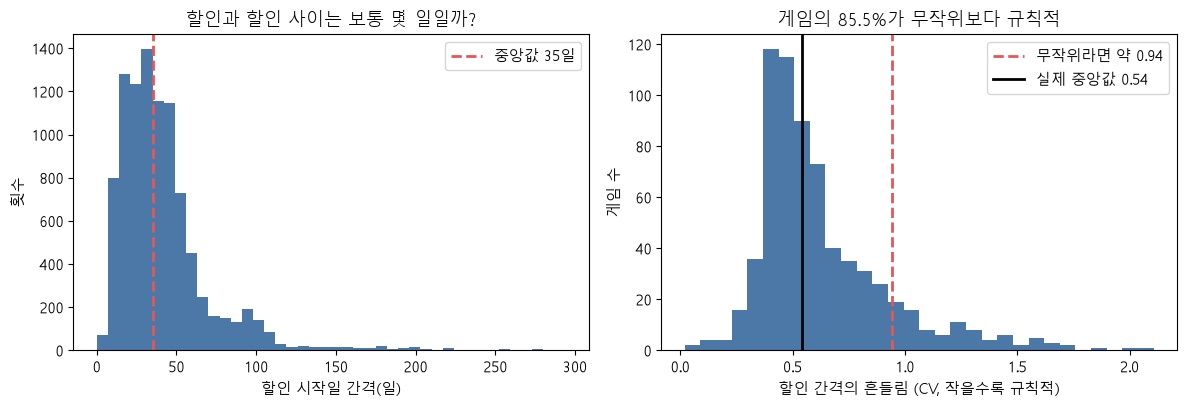

In [21]:
rng = np.random.default_rng(42)

@lru_cache(maxsize=None)
def null_cv(k: int, n_sim: int = 5000) -> float:
    """간격이 k개인 '무작위 할인'의 평균 변동계수 (시뮬레이션)"""
    x = rng.exponential(1.0, size=(n_sim, k))
    return float((x.std(axis=1, ddof=1) / x.mean(axis=1)).mean())

gap_df["cv_null"] = [null_cv(len(g)) for g in gap_df.gaps]
w1 = stats.wilcoxon(gap_df.cv, gap_df.cv_null, alternative="less")
share_regular = (gap_df.cv < gap_df.cv_null).mean()
print(f"실제 CV 중앙값 {gap_df.cv.median():.2f}  vs  무작위 기준 {gap_df.cv_null.median():.2f}")
print(f"무작위보다 규칙적인 게임: {share_regular:.1%}  ·  Wilcoxon 검정 p = {w1.pvalue:.3g}")

pooled = np.concatenate(gap_df.gaps.to_list())
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
ax[0].hist(pooled, bins=np.arange(0, 300, 7), color="#4c78a8")
ax[0].axvline(np.median(pooled), color="#e45756", ls="--", lw=2, label=f"중앙값 {np.median(pooled):.0f}일")
ax[0].set(title="할인과 할인 사이는 보통 몇 일일까?", xlabel="할인 시작일 간격(일)", ylabel="횟수"); ax[0].legend()
ax[1].hist(gap_df.cv, bins=30, color="#4c78a8")
ax[1].axvline(gap_df.cv_null.median(), color="#e45756", ls="--", lw=2, label=f"무작위라면 약 {gap_df.cv_null.median():.2f}")
ax[1].axvline(gap_df.cv.median(), color="black", lw=2, label=f"실제 중앙값 {gap_df.cv.median():.2f}")
ax[1].set(title=f"게임의 {share_regular:.1%}가 무작위보다 규칙적", xlabel="할인 간격의 흔들림 (CV, 작을수록 규칙적)", ylabel="게임 수"); ax[1].legend()
plt.tight_layout(); plt.show()

**차트 읽는 법** 왼쪽은 할인 간격이 어디에 몰리는지, 오른쪽은 게임별 간격의 흔들림(CV)이다. 빨간 점선이 "할인이 무작위였다면 나왔을 값"이고, 막대 대부분이 그 **왼쪽**에 있으면 무작위보다 규칙적이라는 뜻이다.

### H2. 할인은 특정 달에 몰리는가?
달별 **할인 시작 횟수**가 고른지 본다. 달마다 관찰한 날수가 달라서, 기대 횟수는 **관찰한 날수 비율**로 잡았다.

할인 시작 10,688건 · 카이제곱 p = 1.45e-160 · Cramér's V = 0.08


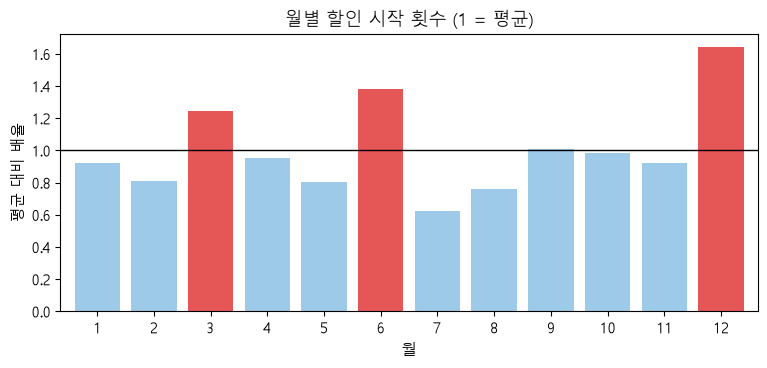

평균보다 15% 이상 많은 달: [3, 6, 12]


In [22]:
exposure = np.zeros(12)
for gid, d in series_by_game.items():
    span = pd.date_range(max(d.day.min(), SINCE), END)
    exposure += np.bincount(span.month - 1, minlength=12)

starts = pd.concat([ev.start for ev in events.values()])
observed = np.bincount(starts.dt.month - 1, minlength=12)
expected = exposure / exposure.sum() * observed.sum()
chi2, p_month = stats.chisquare(observed, expected)
cramers_v = np.sqrt(chi2 / (observed.sum() * 11))               # 효과 크기 (0.1 미만이면 작음)
print(f"할인 시작 {observed.sum():,}건 · 카이제곱 p = {p_month:.3g} · Cramér's V = {cramers_v:.2f}")

ratio = pd.Series(observed / expected, index=range(1, 13))
ax = ratio.plot.bar(figsize=(9, 3.6), color=np.where(ratio > 1.15, "#e45756", "#9ecae9"), width=.8)
ax.axhline(1, color="black", lw=1)
ax.set(title="월별 할인 시작 횟수 (1 = 평균)", xlabel="월", ylabel="평균 대비 배율"); plt.xticks(rotation=0); plt.show()
print("평균보다 15% 이상 많은 달:", [int(m) for m, r in ratio.items() if r > 1.15])

**차트 읽는 법** 막대가 1(검은 선)보다 높으면 그 달에 할인이 평소보다 자주 시작된다. 빨간 달이 스토어의 정기 세일 시기와 겹치는지 본다. 같은 세일에 여러 게임이 같이 들어가서 p값은 실제보다 작게 나온다. 그래서 효과 크기(V)를 함께 본다.

### H3. 서비스의 "평균 간격" 규칙은 얼마나 정확한가? ★
**백테스트**: 각 게임에서 k번째 할인을 **앞의 k-1회만 보고** 예측해서 실제와 비교한다(과거를 가려 놓고 맞히기). 4가지 규칙을 같은 예측에 적용한다.

| 규칙 | 예측 방법 |
|---|---|
| 직전 간격 1개 | 마지막 할인일 + 바로 전 간격 |
| **서비스 규칙** | 마지막 할인일 + 과거 간격의 **평균** |
| 중앙값 규칙 | 마지막 할인일 + 과거 간격의 **중앙값** |
| 전체 중앙값 | 마지막 할인일 + **모든 게임 간격의 중앙값** (예측 시점 이전 것만 사용). 게임 정보를 쓰지 않는 가장 단순한 값 |

In [23]:
# 전체 중앙값: 예측하는 날짜보다 먼저 끝난 모든 게임의 간격만으로 계산 (미래 데이터를 쓰지 않는다)
gap_log = pd.DataFrame([(ev.start.iloc[i], (ev.start.iloc[i] - ev.start.iloc[i - 1]).days)
                        for ev in events.values() for i in range(1, len(ev))], columns=["end", "gap"]).sort_values("end")
end_arr, gap_arr = gap_log.end.to_numpy(), gap_log.gap.to_numpy()

def global_gap_asof(t, min_n=50):
    n = np.searchsorted(end_arr, np.datetime64(t), side="left")
    return float(np.median(gap_arr[:n])) if n >= min_n else np.nan

rows = []
for gid, ev in events.items():
    st = ev.start.tolist()
    for k in range(2, len(st)):                      # 앞의 k회(최소 2회)로 k번째 할인을 예측
        past, actual = st[:k], st[k]
        gaps = [(b - a).days for a, b in zip(past, past[1:])]
        g_all = global_gap_asof(actual)
        if np.isnan(g_all):
            continue
        miss = lambda days: abs((past[-1] + pd.Timedelta(days=float(days)) - actual).days)     # 오차(일)
        rows.append({"직전 간격 1개": miss(gaps[-1]), "서비스 규칙(평균)": miss(round(np.mean(gaps))),
                     "중앙값 규칙": miss(np.median(gaps)), "전체 중앙값": miss(g_all)})
bt = pd.DataFrame(rows)
rules = list(bt.columns)
print(f"백테스트 예측 {len(bt):,}건")

pd.DataFrame({"평균 오차(일)": bt.mean(), "중앙 오차(일)": bt.median(),
              "±14일 안에 맞힌 비율": (bt <= 14).mean()}).round(2)

백테스트 예측 9,014건


,평균 오차(일),중앙 오차(일),±14일 안에 맞힌 비율
직전 간격 1개,27.43,17.0,0.44
서비스 규칙(평균),23.18,14.0,0.51
중앙값 규칙,22.58,14.0,0.53
전체 중앙값,20.75,14.0,0.54


서비스 규칙이 직전 간격보다 정확?   p = 1.83e-112
서비스 규칙이 전체 중앙값보다 정확? p = 1   (p가 1에 가까우면 오히려 더 나쁨)
중앙값 규칙이 평균 규칙보다 정확?   p = 0.127


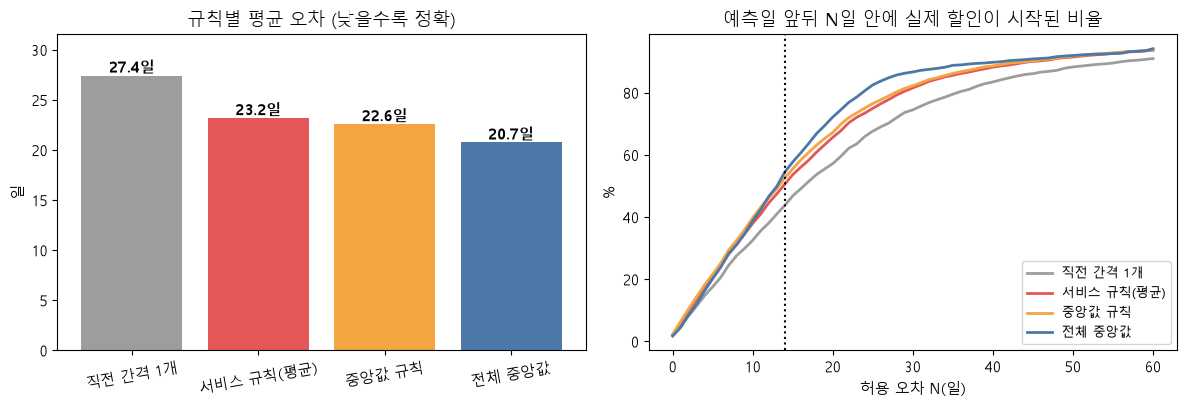

예측일 ± N일 안에 실제 할인이 시작될 확률 (표의 값 = 필요한 N일)


,50%,80%,90%
직전 간격 1개,17,36,57
서비스 규칙(평균),14,29,45
중앙값 규칙,14,28,45
전체 중앙값,14,24,42


In [24]:
# 검정: 오차가 더 작은가? (단측 Wilcoxon)
p_h3a = stats.wilcoxon(bt["서비스 규칙(평균)"], bt["직전 간격 1개"], alternative="less").pvalue
p_h3b = stats.wilcoxon(bt["서비스 규칙(평균)"], bt["전체 중앙값"], alternative="less").pvalue
p_h3c = stats.wilcoxon(bt["중앙값 규칙"], bt["서비스 규칙(평균)"], alternative="less").pvalue
print(f"서비스 규칙이 직전 간격보다 정확?   p = {p_h3a:.3g}")
print(f"서비스 규칙이 전체 중앙값보다 정확? p = {p_h3b:.3g}   (p가 1에 가까우면 오히려 더 나쁨)")
print(f"중앙값 규칙이 평균 규칙보다 정확?   p = {p_h3c:.3g}")

colors = ["#9d9d9d", "#e45756", "#f2a541", "#4c78a8"]
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
mae = bt.mean()
ax[0].bar(rules, mae, color=colors)
for i, v in enumerate(mae):
    ax[0].text(i, v + .3, f"{v:.1f}일", ha="center", fontweight="bold")
ax[0].set(title="규칙별 평균 오차 (낮을수록 정확)", ylabel="일", ylim=(0, mae.max() * 1.15)); ax[0].tick_params(axis="x", labelrotation=10)
tol = np.arange(0, 61)
for r, c in zip(rules, colors):
    ax[1].plot(tol, [(bt[r] <= t).mean() * 100 for t in tol], label=r, color=c, lw=2)
ax[1].axvline(14, color="black", ls=":")
ax[1].set(title="예측일 앞뒤 N일 안에 실제 할인이 시작된 비율", xlabel="허용 오차 N(일)", ylabel="%"); ax[1].legend(fontsize=9)
plt.tight_layout(); plt.show()

q = bt.quantile([.5, .8, .9]).T.round(0).astype(int)
q.columns = ["50%", "80%", "90%"]
print("예측일 ± N일 안에 실제 할인이 시작될 확률 (표의 값 = 필요한 N일)")
q

**차트 읽는 법**
- **왼쪽**: 막대가 낮을수록 정확하다. 서비스 규칙(빨강)이 가장 낮지 않다.
- **오른쪽**: 곡선이 위에 있을수록 같은 허용 오차에서 더 자주 맞힌다. 곡선들이 거의 겹쳐서, **어느 규칙을 써도 절반 정도만 앞뒤 2주 안에 맞힌다.**
- **아래 표**: "예측일 ± N일"로 보여 줄 때 구간을 얼마나 넓혀야 50%, 80%, 90%의 확률로 맞는지 알려 준다. 날짜 하나로 단정하기보다 **구간으로 안내**하는 근거다.

## 5단계. 결론 도출

In [25]:
result = pd.DataFrame([
    ["H1 할인 간격이 무작위보다 규칙적", f"변동계수 중앙값 {gap_df.cv.median():.2f} (무작위 기준 {gap_df.cv_null.median():.2f})", w1.pvalue],
    ["H2 할인이 특정 달에 몰림", f"Cramér's V = {cramers_v:.2f} (효과 작음)", p_month],
    ["H3-a 서비스 규칙이 직전 간격보다 정확", f"{bt['서비스 규칙(평균)'].mean():.1f}일 vs {bt['직전 간격 1개'].mean():.1f}일", p_h3a],
    ["H3-b 서비스 규칙이 전체 중앙값보다 정확", f"{bt['서비스 규칙(평균)'].mean():.1f}일 vs {bt['전체 중앙값'].mean():.1f}일", p_h3b],
    ["H3-c 중앙값 규칙이 평균 규칙보다 정확", f"{bt['중앙값 규칙'].mean():.1f}일 vs {bt['서비스 규칙(평균)'].mean():.1f}일", p_h3c],
], columns=["가설", "핵심 수치", "p값"])
result["판정(α=0.05)"] = result["p값"].map(verdict)
result["p값"] = result["p값"].map(lambda p: f"{p:.3g}" if p < 0.999 else "> 0.999")
result

,가설,핵심 수치,p값,판정(α=0.05)
0,H1 할인 간격이 무작위보다 규칙적,변동계수 중앙값 0.54 (무작위 기준 0.94),5.19e-71,채택 (유의)
1,H2 할인이 특정 달에 몰림,Cramér's V = 0.08 (효과 작음),1.45e-160,채택 (유의)
2,H3-a 서비스 규칙이 직전 간격보다 정확,23.2일 vs 27.4일,1.83e-112,채택 (유의)
3,H3-b 서비스 규칙이 전체 중앙값보다 정확,23.2일 vs 20.7일,> 0.999,기각 못 함 (유의하지 않음)
4,H3-c 중앙값 규칙이 평균 규칙보다 정확,22.6일 vs 23.2일,0.127,기각 못 함 (유의하지 않음)


### 해석

| 가설 | 결과 | 의미 |
|---|---|---|
| H1 규칙성 | **채택** · 변동계수 중앙값 0.54 (무작위라면 0.94), 683개 게임 중 85.5%가 무작위보다 규칙적 | 할인에는 리듬이 있다 |
| H2 시즌성 | **채택, 효과는 작음** · 3·6·12월이 평균보다 15% 이상 많음, Cramér's V = 0.08 | 시즌 영향은 있지만 약하다 |
| H3 예측 정확도 | **부분 채택** · 직전 간격보다는 정확(23.2일 vs 27.4일), 그러나 **전체 중앙값보다는 나쁨**(20.7일) | 게임별로 평균 간격을 구하는 수고가 정확도로 이어지지 않았다 |

**H3에서 더 확인한 것**
- 평균 대신 **중앙값**을 써도 차이가 없다 (22.6일, 평균 규칙과 p=0.13).
- 전체 중앙값은 **예측 시점 이전 데이터만**으로 계산했다. 미래 데이터를 써서 유리했던 것이 아니다.
- 어느 규칙이든 ±14일 안에 맞히는 비율은 약 50%이고, 80%를 맞히려면 ±4주가 필요하다.

### 서비스에 주는 제안
1. **다음 할인일을 날짜 하나가 아니라 구간으로 보여 준다.** 예) "○○ 전후 (±2주 50%, ±4주 80%)".
2. **이력이 짧은 게임은 전체 중앙값(약 35일)을 기본값**으로 쓴다. 평균 규칙이 전체 중앙값보다 나을 이유를 이번 데이터에서 찾지 못했다.
3. **3·6·12월 시즌 안내는 보조 정보로만** 쓴다. 효과가 작아서 구매 판단의 핵심 근거가 되기 어렵다.
4. 규칙 변경은 `docs/contracts/timing_rules.md`에 적고 backend 담당과 협의한다. 이 노트북은 근거 자료다.

### 한계
- "할인"은 모든 스토어 중 한 곳이라도 10% 이상이면 1회로 센다. 키 판매점이 많이 섞여 있어 간격이 짧게(중앙값 약 34일) 나왔다. 공식 스토어 기준이나 더 큰 할인만 보면 달라질 수 있다 (**미검증**).
- 이력이 약 24개월이라 연간 패턴은 최대 2회분이다.
- 분석 대상이 인기작 위주(`analysis/game_list/README.md`)라 전체 게임으로 일반화할 수 없다.
- 같은 세일에 많은 게임이 같이 들어가므로 게임 간 독립을 가정한 p값은 실제보다 작게 나온다.

## 부록 (질문이 나오면)

### A. 계절성을 다른 방법으로 — Prophet
H2를 Prophet(시계열 예측 라이브러리)의 **연간 계절 성분**으로도 본다. 이력이 2년이 안 돼서 예측용이 아니라 **계절 성분을 시각화하는 용도**로만 쓴다. 설치가 안 된 PC에서는 건너뛴다.

Yearly seasonality is enabled with less than 730 days (approximately 2 years) of history. The model may be under-identified, and the trend/seasonality decomposition can be unstable and dependent on the Prophet/Stan version. Consider disabling yearly seasonality or providing more history.
12:26:20 - cmdstanpy - INFO - Chain [1] start processing
12:26:20 - cmdstanpy - INFO - Chain [1] done processing


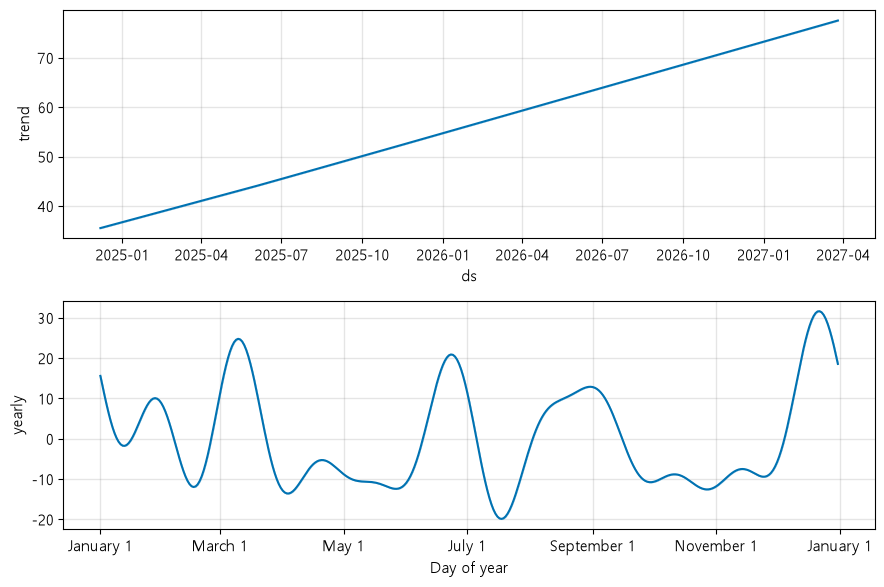

대상 게임: VVVVVV


In [26]:
try:
    from prophet import Prophet

    gid = max(events, key=lambda g: len(events[g]))                    # 할인이 가장 많은 게임 하나
    d = series_by_game[gid].set_index("day").discount_pct
    cal = d[~d.index.duplicated(keep="last")].reindex(pd.date_range(d.index.min(), END)).ffill()
    m = Prophet(yearly_seasonality=True, weekly_seasonality=False, daily_seasonality=False)
    m.fit(pd.DataFrame({"ds": cal.index, "y": cal.values}))
    m.plot_components(m.predict(m.make_future_dataframe(periods=120))); plt.show()
    print("대상 게임:", games.set_index("game_id").name_ko.get(gid, gid))
except ImportError:
    print("prophet 미설치 — 건너뜀 (pip install prophet)")